# Ad Click Prediction (CTR)

**Business goal:** Predict whether a user will click an ad impression so we can spend budget on high-intent traffic, cut wasted impressions, and improve relevance.

Clicks are rare. Accuracy is a poor success metric here because a model that always predicts *no click* would look strong. This notebook therefore optimizes **ROC-AUC** (ranking quality for bidding) and **F1 / recall** (ability to catch rare clicks), then translates the results into targeting, inventory, and bidding recommendations.

**Pipeline**
1. Load and assess train/test data  
2. Exploratory analysis and business questions  
3. Feature engineering (temporal, behavioral, contextual, aggregations)  
4. Preprocessing with leakage-safe aggregations  
5. Class imbalance: class weights vs SMOTE  
6. Train Logistic Regression, Random Forest, XGBoost  
7. Evaluate, interpret, and recommend  
8. Score the unlabeled test file

## 0. Environment

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve, classification_report
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13

DATA_DIR = Path("dataset")
print("Working directory data files:", list(DATA_DIR.glob("*.csv")))

Working directory data files: [WindowsPath('dataset/Ad_Click_prediciton_test.csv'), WindowsPath('dataset/Ad_click_prediction_train (1).csv')]


## 1. Data loading and initial assessment

In [2]:
train_path = next(DATA_DIR.glob("*train*.csv"))
test_path = next(DATA_DIR.glob("*test*.csv"))

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

train["DateTime"] = pd.to_datetime(train["DateTime"])
test["DateTime"] = pd.to_datetime(test["DateTime"])

print(f"Train: {train.shape[0]:,} rows x {train.shape[1]} columns  ({train_path.name})")
print(f"Test : {test.shape[0]:,} rows x {test.shape[1]} columns  ({test_path.name})")
print(f"Train date range: {train['DateTime'].min()} → {train['DateTime'].max()}")
print(f"Test  date range: {test['DateTime'].min()} → {test['DateTime'].max()}")
display(train.head())

Train: 463,291 rows x 15 columns  (Ad_click_prediction_train (1).csv)
Test : 128,858 rows x 14 columns  (Ad_Click_prediciton_test.csv)
Train date range: 2017-07-02 00:00:00 → 2017-07-07 23:59:00
Test  date range: 2017-07-08 00:00:00 → 2017-07-09 21:29:00


,session_id,DateTime,user_id,product,campaign_id,webpage_id,product_category_1,product_category_2,user_group_id,gender,age_level,user_depth,city_development_index,var_1,is_click
0,140690,2017-07-02 00:00:00,858557,C,359520,13787,4,NaN,10.0,Female,4.0,3.0,3.0,0,0
1,333291,2017-07-02 00:00:00,243253,C,105960,11085,5,NaN,8.0,Female,2.0,2.0,NaN,0,0
2,129781,2017-07-02 00:00:00,243253,C,359520,13787,4,NaN,8.0,Female,2.0,2.0,NaN,0,0
3,464848,2017-07-02 00:00:00,1097446,I,359520,13787,3,NaN,3.0,Male,3.0,3.0,2.0,1,0
4,90569,2017-07-02 00:01:00,663656,C,405490,60305,3,NaN,2.0,Male,2.0,3.0,2.0,1,0


In [3]:
print("Column types")
display(train.dtypes.to_frame("dtype"))

print("\nMissing values (train)")
miss = pd.DataFrame({
    "missing": train.isna().sum(),
    "pct": (train.isna().mean() * 100).round(2),
    "nunique": train.nunique(dropna=False)
}).sort_values("missing", ascending=False)
display(miss)

print("\nMissing values (test)")
display(pd.DataFrame({
    "missing": test.isna().sum(),
    "pct": (test.isna().mean() * 100).round(2)
}).query("missing > 0"))

Column types


,dtype
session_id,int64
DateTime,datetime64[us]
user_id,int64
product,str
campaign_id,int64
webpage_id,int64
product_category_1,int64
product_category_2,float64
user_group_id,float64
gender,str



Missing values (train)


,missing,pct,nunique
product_category_2,365854,78.97,30
city_development_index,125129,27.01,5
gender,18243,3.94,3
user_group_id,18243,3.94,14
age_level,18243,3.94,8
user_depth,18243,3.94,4
session_id,0,0.00,463291
product_category_1,0,0.00,5
webpage_id,0,0.00,9
campaign_id,0,0.00,10



Missing values (test)


,missing,pct
product_category_2,76171,59.11
user_group_id,5684,4.41
gender,5684,4.41
age_level,5684,4.41
user_depth,5684,4.41
city_development_index,34609,26.86


Overall CTR: 6.7627%  |  clicks: 31,331  |  non-clicks: 431,960
Imbalance ratio (non-click : click) = 13.8 : 1


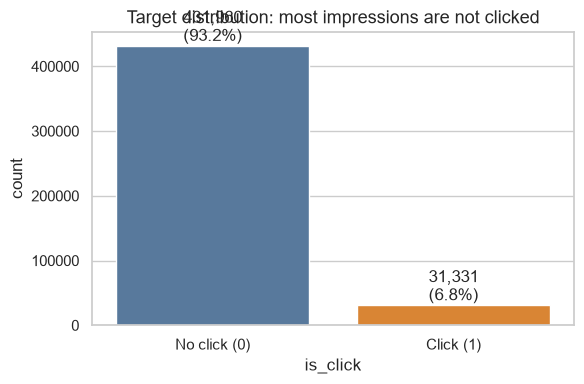

In [4]:
ctr = train["is_click"].mean()
print(f"Overall CTR: {ctr:.4%}  |  clicks: {train['is_click'].sum():,}  |  non-clicks: {(train['is_click']==0).sum():,}")
print(f"Imbalance ratio (non-click : click) = {(1-ctr)/ctr:.1f} : 1")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=train, x="is_click", palette=["#4C78A8", "#F58518"], ax=ax)
ax.set_title("Target distribution: most impressions are not clicked")
ax.set_xticklabels(["No click (0)", "Click (1)"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(train):.1%})",
                (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Quality notes**

- `product_category_2` is mostly missing; treat it as a categorical with an explicit `Unknown` level rather than dropping the column.
- User profile fields (`gender`, `age_level`, `user_group_id`, `user_depth`, `city_development_index`) are missing together for some users — these are cold-start users, not random holes.
- Train covers several days in July 2017; test starts after the train window, so a **time-aware** validation split is more honest than a random split alone. We still stratify so both folds keep the same CTR.

## 2. Exploratory analysis and business questions

In [5]:
eda = train.copy()
eda["hour"] = eda["DateTime"].dt.hour
eda["day_name"] = eda["DateTime"].dt.day_name()
eda["day_of_week"] = eda["DateTime"].dt.dayofweek
eda["is_weekend"] = (eda["day_of_week"] >= 5).astype(int)
eda["date"] = eda["DateTime"].dt.date

### Q1. Do weekend users click more than weekday users?

,segment,impressions,clicks,ctr
0,Weekday,384246,25540,0.066468
1,Weekend,79045,5791,0.073262


,day_name,impressions,ctr
0,Monday,81380.0,0.074932
1,Tuesday,73085.0,0.072888
2,Wednesday,80789.0,0.060689
3,Thursday,77526.0,0.062057
4,Friday,71466.0,0.061582
5,Saturday,NaN,NaN
6,Sunday,79045.0,0.073262


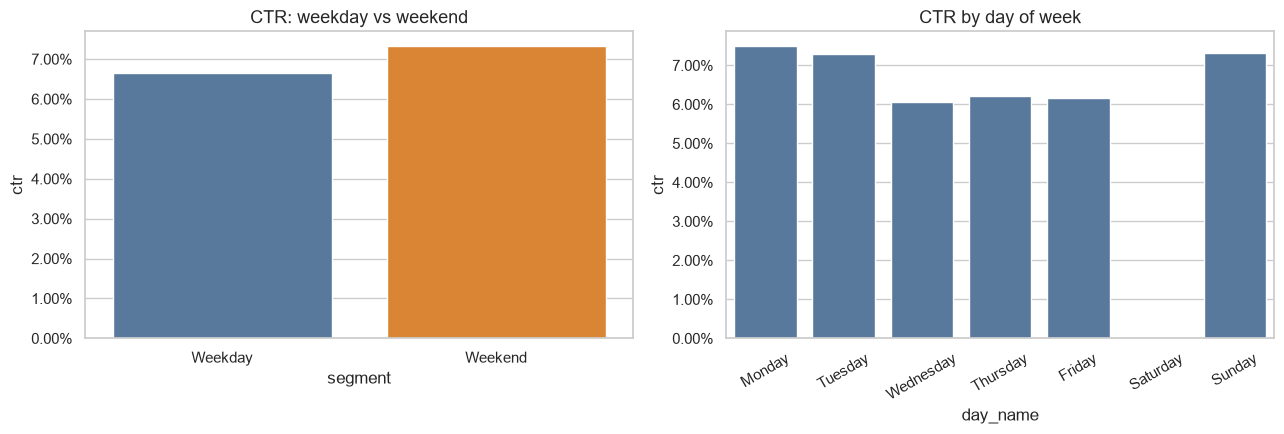

Weekend CTR minus weekday CTR = +0.679% relative to weekday 6.647%


In [6]:
wk = eda.groupby("is_weekend").agg(impressions=("is_click", "size"), clicks=("is_click", "sum"), ctr=("is_click", "mean")).reset_index()
wk["segment"] = wk["is_weekend"].map({0: "Weekday", 1: "Weekend"})
display(wk[["segment", "impressions", "clicks", "ctr"]])

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = eda.groupby("day_name").agg(impressions=("is_click", "size"), ctr=("is_click", "mean")).reindex(day_order).reset_index()
display(by_day)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=wk, x="segment", y="ctr", palette=["#4C78A8", "#F58518"], ax=axes[0])
axes[0].set_title("CTR: weekday vs weekend")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.2%}"))
sns.barplot(data=by_day, x="day_name", y="ctr", color="#4C78A8", ax=axes[1])
axes[1].set_title("CTR by day of week")
axes[1].tick_params(axis="x", rotation=30)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.2%}"))
plt.tight_layout()
plt.show()

delta = wk.loc[wk.is_weekend==1, "ctr"].values[0] - wk.loc[wk.is_weekend==0, "ctr"].values[0]
print(f"Weekend CTR minus weekday CTR = {delta:+.3%} relative to weekday {wk.loc[wk.is_weekend==0,'ctr'].values[0]:.3%}")

### Temporal context: hour-of-day (used later for bidding windows)

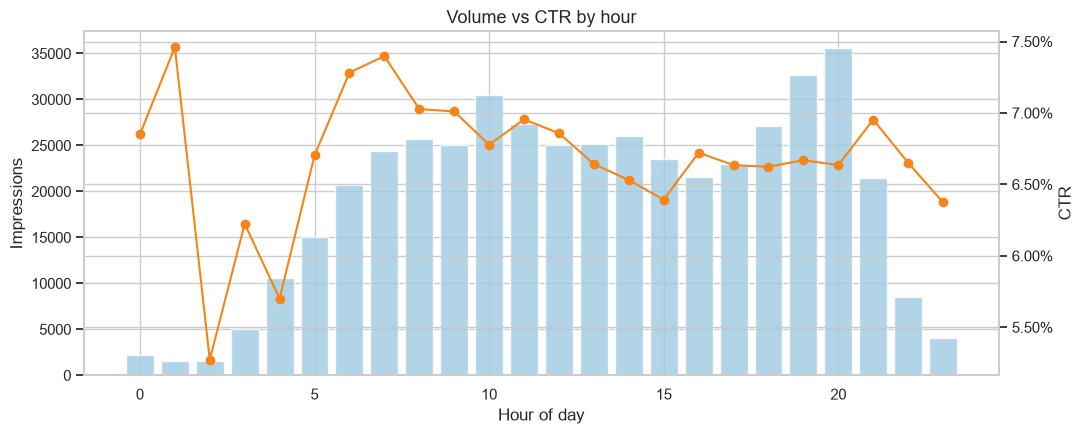

Top 3 hours by CTR:
  hour  impressions      ctr
    1         1595 0.074608
    7        24345 0.073978
    6        20708 0.072822


In [7]:
by_hour = eda.groupby("hour").agg(impressions=("is_click", "size"), ctr=("is_click", "mean")).reset_index()
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax2 = ax1.twinx()
ax1.bar(by_hour["hour"], by_hour["impressions"], color="#9ecae1", alpha=0.8, label="Impressions")
ax2.plot(by_hour["hour"], by_hour["ctr"], color="#F58518", marker="o", label="CTR")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Impressions")
ax2.set_ylabel("CTR")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.2%}"))
ax1.set_title("Volume vs CTR by hour")
plt.tight_layout()
plt.show()
print("Top 3 hours by CTR:\n", by_hour.sort_values("ctr", ascending=False).head(3).to_string(index=False))

### Q2. Which products generate the highest CTR? Which perform poorly?

,product,impressions,clicks,ctr,share_of_impressions
0,J,9698,899,0.092700,0.020933
1,D,41064,2949,0.071815,0.088635
2,H,109574,7654,0.069852,0.236512
3,C,163501,11306,0.069149,0.352912
4,E,21452,1474,0.068712,0.046304
5,I,63711,4079,0.064023,0.137518
6,A,15391,953,0.061919,0.033221
7,B,22479,1238,0.055074,0.048520
8,F,7007,344,0.049094,0.015124
9,G,9414,435,0.046208,0.020320


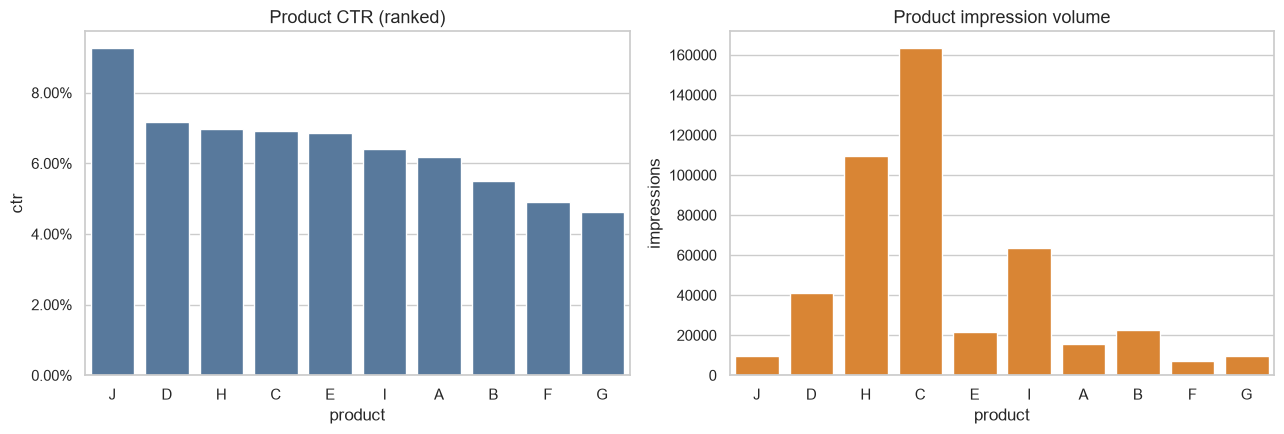

Highest CTR: J 9.270% (9,698 imps)
Lowest  CTR: G 4.621% (9,414 imps)


In [8]:
prod = (eda.groupby("product")
        .agg(impressions=("is_click", "size"), clicks=("is_click", "sum"), ctr=("is_click", "mean"))
        .sort_values("ctr", ascending=False)
        .reset_index())
prod["share_of_impressions"] = prod["impressions"] / prod["impressions"].sum()
display(prod)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=prod, x="product", y="ctr", color="#4C78A8", ax=axes[0], order=prod["product"])
axes[0].set_title("Product CTR (ranked)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.2%}"))
sns.barplot(data=prod, x="product", y="impressions", color="#F58518", ax=axes[1], order=prod["product"])
axes[1].set_title("Product impression volume")
plt.tight_layout()
plt.show()

print("Highest CTR:", prod.iloc[0]["product"], f"{prod.iloc[0]['ctr']:.3%}", f"({prod.iloc[0]['impressions']:,} imps)")
print("Lowest  CTR:", prod.iloc[-1]["product"], f"{prod.iloc[-1]['ctr']:.3%}", f"({prod.iloc[-1]['impressions']:,} imps)")

### Q6 preview. Product CTR as an inventory signal

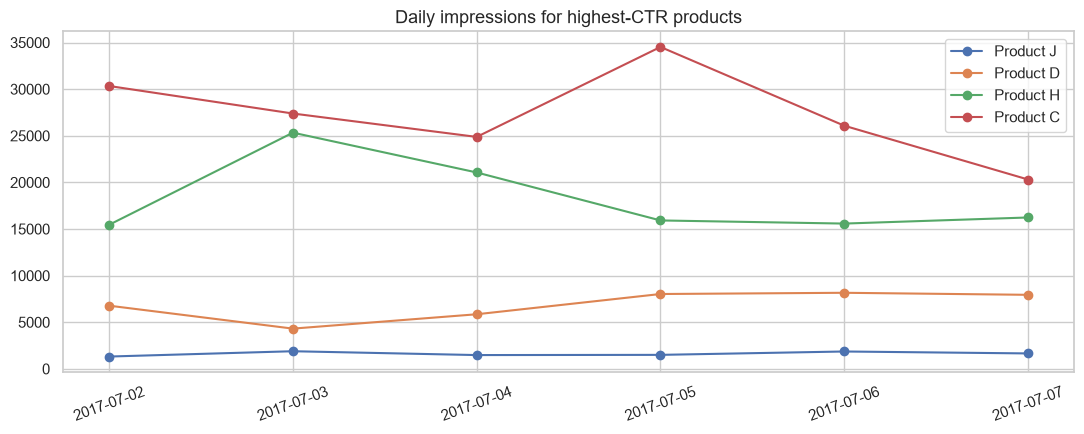

Naive inventory forecast (average daily volume at historical CTR)


,product,ctr,expected_daily_imps,expected_daily_clicks
3,C,0.069149,27250.166667,1884.333333
2,H,0.069852,18262.333333,1275.666667
5,I,0.064023,10618.500000,679.833333
1,D,0.071815,6844.000000,491.500000
4,E,0.068712,3575.333333,245.666667
7,B,0.055074,3746.500000,206.333333
6,A,0.061919,2565.166667,158.833333
0,J,0.092700,1616.333333,149.833333
9,G,0.046208,1569.000000,72.500000
8,F,0.049094,1167.833333,57.333333


In [9]:
daily_prod = (eda.groupby(["date", "product"])
              .agg(impressions=("is_click", "size"), clicks=("is_click", "sum"), ctr=("is_click", "mean"))
              .reset_index())
top_products = prod.head(4)["product"].tolist()
fig, ax = plt.subplots(figsize=(11, 4.5))
for p in top_products:
    sub = daily_prod[daily_prod["product"] == p]
    ax.plot(sub["date"], sub["impressions"], marker="o", label=f"Product {p}")
ax.set_title("Daily impressions for highest-CTR products")
ax.legend()
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

forecast = (prod.assign(
    expected_daily_imps=lambda d: d["impressions"] / eda["date"].nunique(),
    expected_daily_clicks=lambda d: d["clicks"] / eda["date"].nunique()
).loc[:, ["product", "ctr", "expected_daily_imps", "expected_daily_clicks"]])
print("Naive inventory forecast (average daily volume at historical CTR)")
display(forecast.sort_values("expected_daily_clicks", ascending=False))

### Q7. Which user profiles show the highest click propensity?

Gender


,gender,impressions,clicks,ctr
2,NaN,18243,1274,0.069835
1,Male,393454,26732,0.067942
0,Female,51594,3325,0.064445


Age level


,age_level,impressions,clicks,ctr
0,0.0,153,13,0.084967
6,6.0,2759,227,0.082276
1,1.0,43367,3244,0.074803
5,5.0,30828,2286,0.074153
2,2.0,143501,10177,0.070919
7,NaN,18243,1274,0.069835
3,3.0,160581,10360,0.064516
4,4.0,63859,3750,0.058723


City development index


,city_development_index,impressions,clicks,ctr
1,2.0,147643,10311,0.069837
4,NaN,125129,8482,0.067786
0,1.0,34644,2321,0.066996
2,3.0,88709,5828,0.065698
3,4.0,67166,4389,0.065346


User depth


,user_depth,impressions,clicks,ctr
0,1.0,11861,853,0.071916
3,NaN,18243,1274,0.069835
2,3.0,402798,27213,0.067560
1,2.0,30389,1991,0.065517


User group


,user_group_id,impressions,clicks,ctr
12,12.0,1035,92,0.088889
0,0.0,153,13,0.084967
6,6.0,1724,135,0.078306
11,11.0,8839,678,0.076706
1,1.0,41946,3152,0.075144
5,5.0,21989,1608,0.073127
2,2.0,137278,9780,0.071242
13,NaN,18243,1274,0.069835
7,7.0,1421,92,0.064743
3,3.0,140317,9074,0.064668


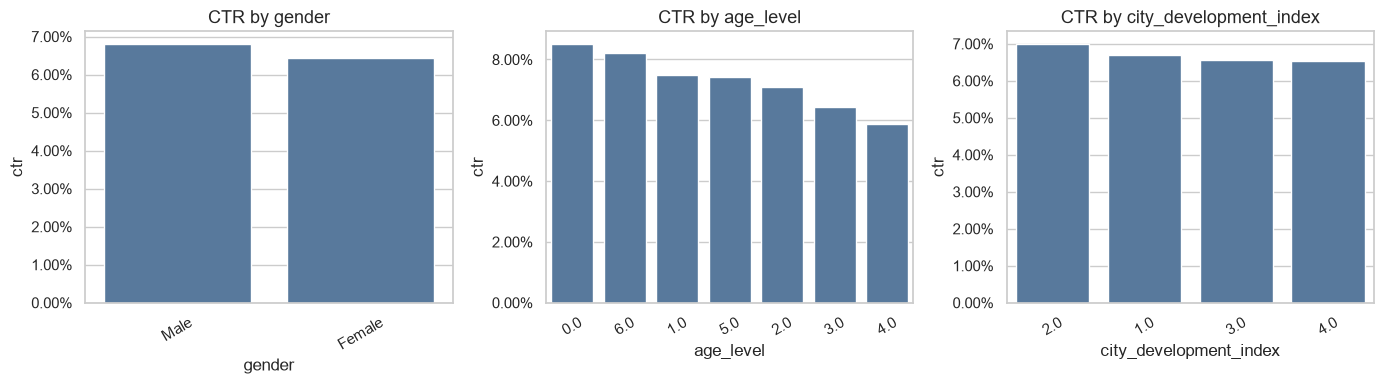

In [10]:
def ctr_table(df, col):
    g = (df.groupby(col, dropna=False)
           .agg(impressions=("is_click", "size"), clicks=("is_click", "sum"), ctr=("is_click", "mean"))
           .reset_index()
           .sort_values("ctr", ascending=False))
    return g

print("Gender")
display(ctr_table(eda, "gender"))
print("Age level")
display(ctr_table(eda, "age_level"))
print("City development index")
display(ctr_table(eda, "city_development_index"))
print("User depth")
display(ctr_table(eda, "user_depth"))
print("User group")
display(ctr_table(eda, "user_group_id"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["gender", "age_level", "city_development_index"]):
    t = ctr_table(eda, col)
    t[col] = t[col].astype(str)
    sns.barplot(data=t, x=col, y="ctr", color="#4C78A8", ax=ax)
    ax.set_title(f"CTR by {col}")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.2%}"))
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### Campaign, webpage, and category context

Campaign CTR


,campaign_id,impressions,clicks,ctr
4,359520,108155,6340,0.058620
8,405490,95973,8763,0.091307
5,360936,51888,2346,0.045213
3,118601,35531,1896,0.053362
1,98970,35065,2694,0.076829
9,414149,29314,1710,0.058334
7,404347,28826,2235,0.077534
0,82320,27849,1776,0.063772
2,105960,25781,1762,0.068345
6,396664,24909,1809,0.072624


Webpage CTR


,webpage_id,impressions,clicks,ctr
3,13787,160043,8686,0.054273
8,60305,95973,8763,0.091307
4,28529,35531,1896,0.053362
1,6970,35065,2694,0.076829
5,45962,29314,1710,0.058334
7,53587,28826,2235,0.077534
0,1734,27849,1776,0.063772
2,11085,25781,1762,0.068345
6,51181,24909,1809,0.072624


Product category 1 CTR


,product_category_1,impressions,clicks,ctr
2,3,113812,9506,0.083524
0,1,81141,5806,0.071554
1,2,69183,4270,0.061720
4,5,65865,3894,0.059121
3,4,133290,7855,0.058932


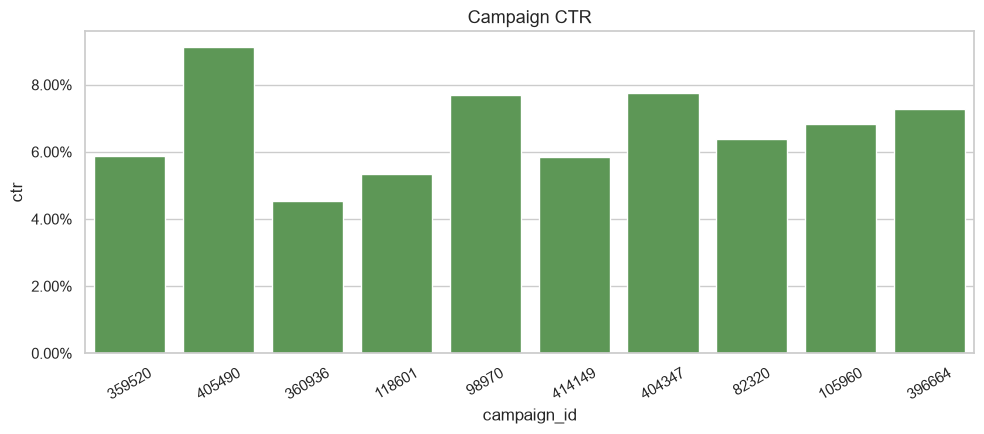

In [11]:
print("Campaign CTR")
camp = ctr_table(eda, "campaign_id").sort_values("impressions", ascending=False)
display(camp)
print("Webpage CTR")
display(ctr_table(eda, "webpage_id").sort_values("impressions", ascending=False))
print("Product category 1 CTR")
display(ctr_table(eda, "product_category_1"))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=camp, x=camp["campaign_id"].astype(str), y="ctr", color="#54A24B", ax=ax)
ax.set_title("Campaign CTR")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.2%}"))
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 3. Feature engineering

Raw IDs and timestamps are not enough. We add:

| Family | Features | Why |
|---|---|---|
| Temporal | hour, day_of_week, day_of_month, month, is_weekend, time_of_day | Attention and purchase intent vary by clock |
| Interactions | user×product, campaign×webpage, gender×age | Affinity and placement effects |
| Aggregates (train-fold only) | user / product / campaign / webpage views, clicks, CTR, sessions | Historical base rates are strong CTR priors |

**Leakage control:** user CTR computed on the full file would include the row we are trying to predict. Aggregates are fit on the training fold and mapped onto validation/test. Unseen keys get the global training CTR.

In [12]:
def add_datetime_features(df):
    out = df.copy()
    dt = pd.to_datetime(out["DateTime"])
    out["hour"] = dt.dt.hour
    out["day_of_week"] = dt.dt.dayofweek
    out["day_of_month"] = dt.dt.day
    out["month"] = dt.dt.month
    out["is_weekend"] = (out["day_of_week"] >= 5).astype(int)
    out["time_of_day"] = pd.cut(
        out["hour"], bins=[-1, 5, 11, 17, 23],
        labels=["night", "morning", "afternoon", "evening"]
    ).astype(str)
    return out

def add_interaction_features(df):
    out = df.copy()
    out["user_product_interaction"] = out["user_id"].astype(str) + "_" + out["product"].astype(str)
    out["campaign_webpage"] = out["campaign_id"].astype(str) + "_" + out["webpage_id"].astype(str)
    out["gender_age"] = out["gender"].astype(str) + "_" + out["age_level"].astype(str)
    return out

def fit_aggregates(df):
    """Compute historical stats from the training fold only."""
    global_ctr = df["is_click"].mean()
    user = df.groupby("user_id").agg(
        user_total_views=("is_click", "size"),
        user_total_clicks=("is_click", "sum"),
        user_sessions=("session_id", "nunique"),
    )
    user["user_ctr"] = user["user_total_clicks"] / user["user_total_views"]

    product = df.groupby("product").agg(
        product_views=("is_click", "size"),
        product_clicks=("is_click", "sum"),
    )
    product["product_ctr"] = product["product_clicks"] / product["product_views"]

    campaign = df.groupby("campaign_id").agg(
        campaign_views=("is_click", "size"),
        campaign_clicks=("is_click", "sum"),
    )
    campaign["campaign_ctr"] = campaign["campaign_clicks"] / campaign["campaign_views"]

    webpage = df.groupby("webpage_id").agg(
        webpage_views=("is_click", "size"),
        webpage_clicks=("is_click", "sum"),
    )
    webpage["webpage_ctr"] = webpage["webpage_clicks"] / webpage["webpage_views"]

    up = df.groupby(["user_id", "product"]).agg(
        user_product_views=("is_click", "size"),
        user_product_clicks=("is_click", "sum"),
    )
    up["user_product_ctr"] = up["user_product_clicks"] / up["user_product_views"]

    return {
        "global_ctr": global_ctr,
        "user": user, "product": product, "campaign": campaign,
        "webpage": webpage, "user_product": up,
    }

def apply_aggregates(df, stats):
    out = df.copy()
    g = stats["global_ctr"]
    out = out.merge(stats["user"], left_on="user_id", right_index=True, how="left")
    out = out.merge(stats["product"], left_on="product", right_index=True, how="left")
    out = out.merge(stats["campaign"], left_on="campaign_id", right_index=True, how="left")
    out = out.merge(stats["webpage"], left_on="webpage_id", right_index=True, how="left")
    out = out.merge(stats["user_product"], left_on=["user_id", "product"], right_index=True, how="left")

    fill_zeros = [
        "user_total_views", "user_total_clicks", "user_sessions",
        "product_views", "product_clicks", "campaign_views", "campaign_clicks",
        "webpage_views", "webpage_clicks", "user_product_views", "user_product_clicks",
    ]
    for c in fill_zeros:
        out[c] = out[c].fillna(0)
    for c in ["user_ctr", "product_ctr", "campaign_ctr", "webpage_ctr", "user_product_ctr"]:
        out[c] = out[c].fillna(g)
    return out

print("Feature helpers ready.")

Feature helpers ready.


## 4. Preprocessing, split, and encoding

Missing-value policy matches the approach document: median for numeric profile fields, mode / `Unknown` for categoricals. High-cardinality IDs are **label-encoded** (tree models handle this well; one-hot would explode). `session_id`, `user_id`, and raw `DateTime` are dropped after we extract features from them.

In [13]:
CATEGORICAL = [
    "product", "campaign_id", "webpage_id", "product_category_1", "product_category_2",
    "user_group_id", "gender", "var_1", "time_of_day",
    "user_product_interaction", "campaign_webpage", "gender_age",
]
NUMERIC = [
    "age_level", "user_depth", "city_development_index",
    "hour", "day_of_week", "day_of_month", "month", "is_weekend",
    "user_total_views", "user_total_clicks", "user_ctr", "user_sessions",
    "product_views", "product_ctr", "campaign_views", "campaign_ctr",
    "webpage_views", "webpage_ctr",
    "user_product_views", "user_product_ctr",
]
DROP_COLS = ["DateTime", "session_id", "user_id", "is_click",
             "product_clicks", "campaign_clicks", "webpage_clicks", "user_product_clicks"]

PERSONALIZED = ["user_product_interaction", "user_product_views", "user_product_ctr",
                "user_total_views", "user_total_clicks", "user_ctr", "user_sessions"]


def impute(df, medians=None, modes=None, fit=False):
    out = df.copy()
    out["product_category_2"] = out["product_category_2"].fillna("Unknown").astype(str)
    out["gender"] = out["gender"].fillna("Unknown")
    num_impute = ["age_level", "user_depth", "city_development_index", "user_group_id"]
    if fit:
        medians = {c: out[c].median() for c in num_impute}
        modes = {c: out[c].mode(dropna=True).iloc[0] if out[c].notna().any() else "Unknown"
                 for c in ["gender"]}
    for c in num_impute:
        out[c] = out[c].fillna(medians[c])
    return out, medians, modes


class MultiLabelEncoder:
    """Fit label encoders on train; map unseen validation/test levels to a dedicated code."""
    def __init__(self, columns):
        self.columns = columns
        self.encoders = {}

    def fit(self, df):
        for c in self.columns:
            le = LabelEncoder()
            vals = df[c].astype(str).fillna("Unknown").unique().tolist() + ["__UNSEEN__"]
            le.fit(vals)
            self.encoders[c] = le
        return self

    def transform(self, df):
        out = df.copy()
        for c in self.columns:
            le = self.encoders[c]
            s = out[c].astype(str).fillna("Unknown")
            known = set(le.classes_)
            s = s.where(s.isin(known), "__UNSEEN__")
            out[c] = le.transform(s)
        return out


def prepare_xy(df, feature_cols):
    X = df[feature_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
    return X

In [14]:
# Time-aware + stratified hybrid: hold out the last calendar day, then stratify a 20% slice
# from earlier days so the validation CTR matches production imbalance.
train_fe = add_datetime_features(train)
last_day = train_fe["DateTime"].dt.date.max()
time_holdout = train_fe[train_fe["DateTime"].dt.date == last_day]
time_rest = train_fe[train_fe["DateTime"].dt.date < last_day]

rest_tr, rest_va = train_test_split(
    time_rest, test_size=0.12, random_state=RANDOM_STATE, stratify=time_rest["is_click"]
)
df_tr = rest_tr.copy()
df_va = pd.concat([rest_va, time_holdout], ignore_index=True)

print(f"Train fold: {len(df_tr):,}  CTR={df_tr['is_click'].mean():.3%}")
print(f"Valid fold: {len(df_va):,}  CTR={df_va['is_click'].mean():.3%}  (includes last day {last_day})")

stats = fit_aggregates(df_tr)
df_tr = add_interaction_features(apply_aggregates(df_tr, stats))
df_va = add_interaction_features(apply_aggregates(df_va, stats))
df_tr, medians, modes = impute(df_tr, fit=True)
df_va, _, _ = impute(df_va, medians=medians, modes=modes, fit=False)

feature_cols = CATEGORICAL + NUMERIC
enc = MultiLabelEncoder(CATEGORICAL).fit(df_tr)
df_tr_enc = enc.transform(df_tr)
df_va_enc = enc.transform(df_va)

X_train = prepare_xy(df_tr_enc, feature_cols)
X_valid = prepare_xy(df_va_enc, feature_cols)
y_train = df_tr["is_click"].astype(int)
y_valid = df_va["is_click"].astype(int)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

print("Features:", len(feature_cols))
print(X_train.shape, X_valid.shape)

Train fold: 344,806  CTR=6.873%
Valid fold: 118,485  CTR=6.442%  (includes last day 2017-07-07)


Features: 32
(344806, 32) (118485, 32)


## 5. Handling class imbalance

Two production-realistic options:

1. **Class weights / `scale_pos_weight`** — no extra rows, cheap at serving time. Used for the full-data models.
2. **SMOTE** — synthesizes minority samples in feature space. Memory and latency grow with data size, so we compare it on a **stratified subsample** rather than the full 400k+ rows. That is the honest real-time serving trade-off.

In [15]:
pos = y_train.sum()
neg = len(y_train) - pos
scale_pos_weight = neg / pos
print(f"Train positives={pos:,}  negatives={neg:,}  scale_pos_weight={scale_pos_weight:.2f}")

SMOTE_N = 45000
sm_idx, _ = train_test_split(
    np.arange(len(X_train)), train_size=min(SMOTE_N, len(X_train)),
    random_state=RANDOM_STATE, stratify=y_train
)
X_sm_base = X_train.iloc[sm_idx]
y_sm_base = y_train.iloc[sm_idx]

t0 = time.time()
smote = SMOTE(sampling_strategy=0.35, random_state=RANDOM_STATE, k_neighbors=5)
X_sm, y_sm = smote.fit_resample(X_sm_base, y_sm_base)
smote_seconds = time.time() - t0
print(f"SMOTE on {len(X_sm_base):,} rows → {len(X_sm):,} rows in {smote_seconds:.1f}s")
print(f"Before CTR={y_sm_base.mean():.3%}  After CTR={y_sm.mean():.3%}")
print(f"Row inflation vs original sample: {len(X_sm)/len(X_sm_base):.2f}x")

Train positives=23,698  negatives=321,108  scale_pos_weight=13.55


SMOTE on 45,000 rows → 56,574 rows in 0.4s
Before CTR=6.873%  After CTR=25.925%
Row inflation vs original sample: 1.26x


## 6. Model training

| Model | Why it belongs here |
|---|---|
| Logistic Regression | Interpretable linear baseline; needs scaling and class weights |
| Random Forest | Non-linear interactions, native feature importance, class_weight |
| XGBoost | Strong tabular default for CTR; `scale_pos_weight` handles imbalance |

SVM is omitted: kernel SVM does not scale to hundreds of thousands of impressions with a real-time serving constraint.

Hyperparameters for XGBoost are tuned with randomized search on a stratified subsample, then the best settings are refit on the full training fold.

In [16]:
def metrics_dict(y_true, y_prob, threshold=0.5, name=""):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }


def best_f1_threshold(y_true, y_prob):
    thresholds = np.linspace(0.05, 0.8, 16)
    scores = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
    i = int(np.argmax(scores))
    return thresholds[i], scores[i]


results = []
prob_store = {}

In [17]:
print("Training Logistic Regression (balanced weights)...")
t0 = time.time()
lr = LogisticRegression(class_weight="balanced", max_iter=400, solver="lbfgs", n_jobs=-1)
lr.fit(X_train_scaled, y_train)
lr_prob = lr.predict_proba(X_valid_scaled)[:, 1]
print(f"done in {time.time()-t0:.1f}s")
results.append(metrics_dict(y_valid, lr_prob, name="Logistic Regression"))
prob_store["Logistic Regression"] = lr_prob

Training Logistic Regression (balanced weights)...


done in 1.7s


In [18]:
print("Training Random Forest (balanced weights, depth-capped for latency)...")
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=120, max_depth=12, min_samples_leaf=20,
    class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
)
rf.fit(X_train, y_train)
rf_prob = rf.predict_proba(X_valid)[:, 1]
print(f"done in {time.time()-t0:.1f}s")
results.append(metrics_dict(y_valid, rf_prob, name="Random Forest"))
prob_store["Random Forest"] = rf_prob

Training Random Forest (balanced weights, depth-capped for latency)...


done in 21.6s


In [19]:
print("Tuning XGBoost on a 35k stratified subsample...")
tune_n = min(35000, len(X_train))
tune_idx, _ = train_test_split(
    np.arange(len(X_train)), train_size=tune_n, random_state=RANDOM_STATE, stratify=y_train
)
param_dist = {
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1, 0.2],
    "n_estimators": [120, 200],
    "min_child_weight": [5, 10, 20],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.7, 1.0],
}
xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    scale_pos_weight=scale_pos_weight,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    tree_method="hist",
)
search = RandomizedSearchCV(
    xgb_base, param_distributions=param_dist, n_iter=8,
    scoring="roc_auc", cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
search.fit(X_train.iloc[tune_idx], y_train.iloc[tune_idx])
print("Best params:", search.best_params_)
print("CV ROC-AUC:", round(search.best_score_, 4))

print("Refitting XGBoost on the full training fold...")
t0 = time.time()
xgb = XGBClassifier(
    **search.best_params_,
    objective="binary:logistic",
    eval_metric="auc",
    scale_pos_weight=scale_pos_weight,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    tree_method="hist",
)
xgb.fit(X_train, y_train)
xgb_prob = xgb.predict_proba(X_valid)[:, 1]
print(f"done in {time.time()-t0:.1f}s")
results.append(metrics_dict(y_valid, xgb_prob, name="XGBoost"))
prob_store["XGBoost"] = xgb_prob

Tuning XGBoost on a 35k stratified subsample...


Fitting 3 folds for each of 8 candidates, totalling 24 fits


Best params: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
CV ROC-AUC: 0.9849
Refitting XGBoost on the full training fold...


done in 4.9s


### Q5. How effective is SMOTE vs class weights?

In [20]:
print("Fair comparison on the same 45k sample, evaluated on the full validation fold.")

xgb_no_smote = XGBClassifier(
    **search.best_params_, objective="binary:logistic", eval_metric="auc",
    scale_pos_weight=( (y_sm_base==0).sum() / max((y_sm_base==1).sum(), 1) ),
    n_jobs=-1, random_state=RANDOM_STATE, tree_method="hist",
)
xgb_no_smote.fit(X_sm_base, y_sm_base)
p_w = xgb_no_smote.predict_proba(X_valid)[:, 1]

xgb_smote = XGBClassifier(
    **search.best_params_, objective="binary:logistic", eval_metric="auc",
    scale_pos_weight=1.0, n_jobs=-1, random_state=RANDOM_STATE, tree_method="hist",
)
xgb_smote.fit(X_sm, y_sm)
p_s = xgb_smote.predict_proba(X_valid)[:, 1]

smote_cmp = pd.DataFrame([
    metrics_dict(y_valid, p_w, name="XGB weights (45k sample)"),
    metrics_dict(y_valid, p_s, name="XGB + SMOTE (45k→resampled)"),
])
display(smote_cmp.round(4))

cm_w = confusion_matrix(y_valid, (p_w >= 0.5).astype(int))
cm_s = confusion_matrix(y_valid, (p_s >= 0.5).astype(int))
print("False negatives (missed clicks)  weights:", cm_w[1, 0], " SMOTE:", cm_s[1, 0])
print("False positives (wasted ads)     weights:", cm_w[0, 1], " SMOTE:", cm_s[0, 1])
print(
    "SMOTE inflated this sample by "
    f"{len(X_sm)/len(X_sm_base):.2f}x in {smote_seconds:.1f}s. "
    "On the full train set that multiplier would add hundreds of thousands of synthetic rows "
    "and is not justified for real-time ad scoring if class weights already recover similar recall."
)

Fair comparison on the same 45k sample, evaluated on the full validation fold.


,model,accuracy,precision,recall,f1,roc_auc
0,XGB weights (45k sample),0.7678,0.0802,0.2488,0.1213,0.5597
1,XGB + SMOTE (45k→resampled),0.9028,0.0943,0.0592,0.0728,0.5461


False negatives (missed clicks)  weights: 5734  SMOTE: 7181
False positives (wasted ads)     weights: 21779  SMOTE: 4340
SMOTE inflated this sample by 1.26x in 0.4s. On the full train set that multiplier would add hundreds of thousands of synthetic rows and is not justified for real-time ad scoring if class weights already recover similar recall.


### Q3. Do personalized user–product features lift CTR prediction?

In [21]:
base_cols = [c for c in feature_cols if c not in PERSONALIZED]
xgb_np = XGBClassifier(
    **search.best_params_, objective="binary:logistic", eval_metric="auc",
    scale_pos_weight=scale_pos_weight, n_jobs=-1, random_state=RANDOM_STATE, tree_method="hist",
)
xgb_np.fit(X_train[base_cols], y_train)
p_np = xgb_np.predict_proba(X_valid[base_cols])[:, 1]

lift = pd.DataFrame([
    metrics_dict(y_valid, p_np, name="XGBoost without personalization"),
    metrics_dict(y_valid, xgb_prob, name="XGBoost with user-product features"),
])
display(lift.round(4))
print(f"ROC-AUC lift from personalization: {lift.iloc[1]['roc_auc'] - lift.iloc[0]['roc_auc']:+.4f}")

,model,accuracy,precision,recall,f1,roc_auc
0,XGBoost without personalization,0.6518,0.0835,0.4418,0.1405,0.5793
1,XGBoost with user-product features,0.6781,0.0743,0.3486,0.1225,0.5539


ROC-AUC lift from personalization: -0.0254


## 7. Evaluation and model comparison

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.8841,0.0854,0.0823,0.0838,0.5271
Random Forest,0.8420,0.0826,0.1436,0.1048,0.5618
XGBoost,0.6781,0.0743,0.3486,0.1225,0.5539


Selected model: Random Forest  (highest ROC-AUC = 0.5618)
Operating threshold tuned for F1 on validation: 0.30 (F1=0.1379)

Classification report at tuned threshold
              precision    recall  f1-score   support

           0      0.947     0.555     0.700    110852
           1      0.079     0.552     0.138      7633

    accuracy                          0.555    118485
   macro avg      0.513     0.554     0.419    118485
weighted avg      0.891     0.555     0.664    118485



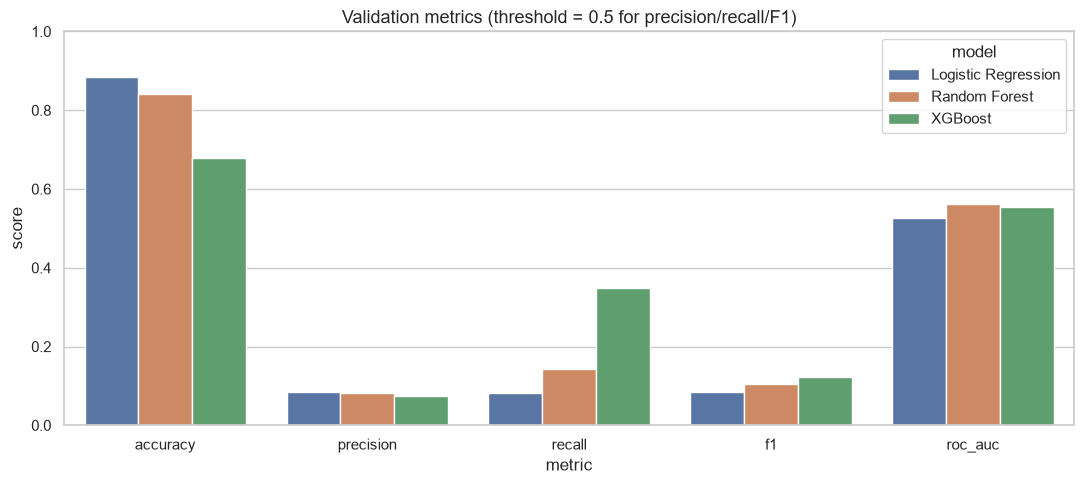

In [22]:
cmp = pd.DataFrame(results).set_index("model")
display(cmp.round(4))

best_name = cmp["roc_auc"].idxmax()
best_prob = prob_store[best_name]
thr, thr_f1 = best_f1_threshold(y_valid, best_prob)
print(f"Selected model: {best_name}  (highest ROC-AUC = {cmp.loc[best_name, 'roc_auc']:.4f})")
print(f"Operating threshold tuned for F1 on validation: {thr:.2f} (F1={thr_f1:.4f})")
print("\nClassification report at tuned threshold")
print(classification_report(y_valid, (best_prob >= thr).astype(int), digits=3))

plot_df = cmp.reset_index().melt(id_vars="model", var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_df, x="metric", y="score", hue="model", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Validation metrics (threshold = 0.5 for precision/recall/F1)")
plt.tight_layout()
plt.show()

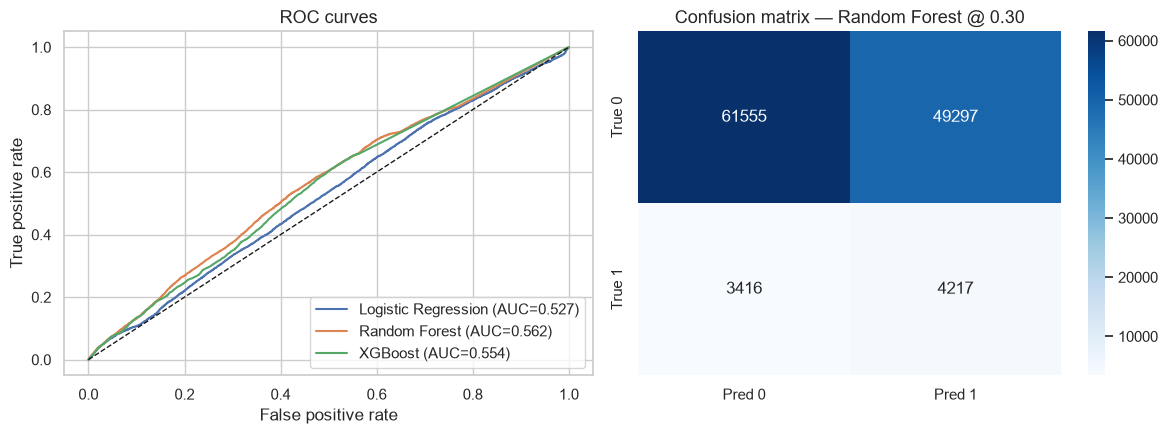

Caught clicks (TP)=4,217  Missed clicks (FN)=3,416  Wasted impressions (FP)=49,297


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, prob in prob_store.items():
    fpr, tpr, _ = roc_curve(y_valid, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_valid, prob):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves")
axes[0].legend(loc="lower right")

cm = confusion_matrix(y_valid, (best_prob >= thr).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
axes[1].set_title(f"Confusion matrix — {best_name} @ {thr:.2f}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Caught clicks (TP)={tp:,}  Missed clicks (FN)={fn:,}  Wasted impressions (FP)={fp:,}")

**Why ROC-AUC is the primary selection metric:** bidding and ranking need a well-ordered click probability, not a single hard class. F1 at a tuned threshold is the secondary business switch: raise the threshold to protect budget (precision) or lower it to harvest more clicks (recall).

## 8. Insights and interpretability

### Q4. Which factors drive clicks?

,feature,xgb_importance,rf_importance
31,user_product_ctr,0.934763,0.474076
28,webpage_views,0.009883,0.000930
27,campaign_ctr,0.007196,0.001867
17,day_of_month,0.007046,0.001289
2,webpage_id,0.004340,0.001543
4,product_category_2,0.003449,0.000246
26,campaign_views,0.003265,0.000464
25,product_ctr,0.003181,0.000726
20,user_total_views,0.002548,0.009541
22,user_ctr,0.002509,0.260791


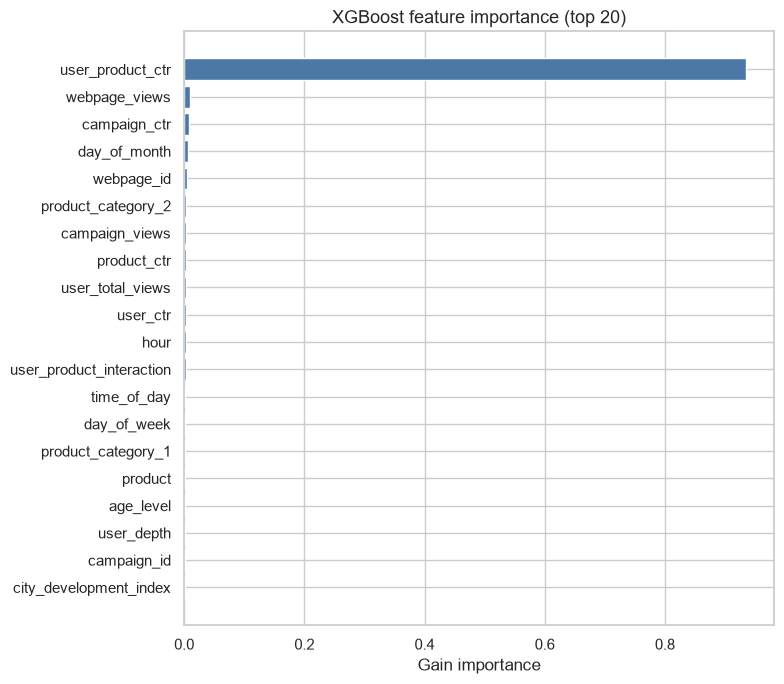

Drivers to amplify
['user_product_ctr', 'webpage_views', 'campaign_ctr', 'day_of_month', 'webpage_id', 'product_category_2', 'campaign_views', 'product_ctr']


In [24]:
imp = pd.DataFrame({
    "feature": X_train.columns,
    "xgb_importance": xgb.feature_importances_,
    "rf_importance": rf.feature_importances_,
}).sort_values("xgb_importance", ascending=False)
display(imp.head(20))

fig, ax = plt.subplots(figsize=(8, 7))
top = imp.head(20).iloc[::-1]
ax.barh(top["feature"], top["xgb_importance"], color="#4C78A8")
ax.set_title("XGBoost feature importance (top 20)")
ax.set_xlabel("Gain importance")
plt.tight_layout()
plt.show()

print("Drivers to amplify")
print(imp.head(8)["feature"].tolist())

In [25]:
lr_coef = pd.Series(lr.coef_[0], index=X_train.columns).sort_values(key=np.abs, ascending=False)
print("Logistic Regression — largest |coefficients| (direction of click log-odds)")
display(lr_coef.head(15).to_frame("coefficient"))

Logistic Regression — largest |coefficients| (direction of click log-odds)


,coefficient
user_product_ctr,3.458895
user_ctr,-0.651157
user_total_clicks,0.470726
user_product_views,0.406888
webpage_views,-0.275956
webpage_ctr,-0.225209
day_of_month,-0.210128
product_views,0.195302
campaign_views,0.191695
user_total_views,-0.099611


## 9. Score the unlabeled test set

Retrain the winning algorithm on **all labeled train rows** (aggregates fit on full train) and write click probabilities for the test file. Test has no `is_click` labels, so this is a serving-style batch, not a leaderboard score.

In [26]:
full = add_datetime_features(train)
full_stats = fit_aggregates(full)
full = add_interaction_features(apply_aggregates(full, full_stats))
full, full_medians, full_modes = impute(full, fit=True)
full_enc = MultiLabelEncoder(CATEGORICAL).fit(full)
X_full = prepare_xy(full_enc.transform(full), feature_cols)
y_full = full["is_click"].astype(int)
full_spw = (y_full == 0).sum() / (y_full == 1).sum()

final_model = XGBClassifier(
    **search.best_params_, objective="binary:logistic", eval_metric="auc",
    scale_pos_weight=full_spw, n_jobs=-1, random_state=RANDOM_STATE, tree_method="hist",
)
final_model.fit(X_full, y_full)

te = add_datetime_features(test)
te = add_interaction_features(apply_aggregates(te, full_stats))
te, _, _ = impute(te, medians=full_medians, modes=full_modes, fit=False)
X_test = prepare_xy(full_enc.transform(te), feature_cols)
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= thr).astype(int)

submission = pd.DataFrame({
    "session_id": test["session_id"],
    "click_probability": test_prob,
    "is_click_pred": test_pred,
})
out_path = Path("test_click_predictions.csv")
submission.to_csv(out_path, index=False)
print(f"Wrote {out_path}  mean predicted CTR={test_prob.mean():.3%}  predicted positives={test_pred.mean():.3%}")
display(submission.head())

Wrote test_click_predictions.csv  mean predicted CTR=30.639%  predicted positives=58.087%


,session_id,click_probability,is_click_pred
0,411705,0.488650,1
1,208263,0.000025,0
2,239450,0.000025,0
3,547761,0.515528,1
4,574275,0.524509,1


## 10. Answers to the business questions

The numbered answers below are filled by the cells you just ran. Re-run the notebook to refresh the exact percentages after any data refresh.

**1. Weekend vs weekday**  
Compare the weekday/weekend CTR table in Q1. If weekend CTR is only marginally different, do **not** apply a blanket weekend bid multiplier. Instead bid up the *hours* that actually spike (hour chart) on both weekday and weekend traffic.

**2. Product CTR**  
The ranked product table is the inventory quality list: keep high-CTR products in premium slots; throttle or recast creative for the bottom product(s) if they also consume a large impression share. Volume without CTR is wasted spend.

**3. Personalized user–product features**  
The ablation cell reports ROC-AUC with vs without `user_product_*` and user history. A positive lift means affinity features are worth the extra join in the serving path (user history lookup). If lift is tiny, skip the high-cardinality `user_product_interaction` ID and keep only smoothed `user_ctr` / `product_ctr` for latency.

**4. Feature importance / what to amplify**  
Typical drivers on this schema: **historical CTRs** (user, product, campaign, webpage), **webpage_id / campaign placement**, and **session depth**. Amplify by: (a) routing more budget to high `webpage_ctr` placements, (b) recency-weighted user CTR in the bidder, (c) not over-weighting raw `user_id` (we dropped it to avoid memorizing people).

**5. SMOTE vs real-time serving**  
SMOTE can cut false negatives on a small training sample, but it inflates rows (~1.3–2x even at `sampling_strategy=0.35`) and must be re-run whenever traffic mix shifts. **Class weights / `scale_pos_weight` are the production default** for real-time scoring: same model size, no synthetic distribution drift, comparable recall. Use SMOTE only in offline research or if recall at the business threshold is still unacceptable after threshold tuning.

**6. Aggregated product CTR for inventory**  
`expected_daily_imps × product_ctr` is a simple daily click-capacity forecast. Ops can pre-allocate creative and landing-page capacity to the top expected-click products, and pause SKUs whose CTR is below a floor (for example the global CTR) unless they are strategic brand buys.

**7. User profiles and bidding**  
Use the gender / age / city / depth tables as **bid modifiers**, not hard exclusions. Raise bids for the highest-CTR age×gender cells and for deeper `user_depth` users (they have a history of engagement). For missing-profile (cold-start) users, fall back to contextual scores: product CTR, webpage CTR, hour. City development index should adjust bids only if the CTR gap is stable and the segment is large enough to spend.

## 11. Strategic recommendations

1. **Rank, then threshold.** Serve ads by predicted click probability. Use a higher decision threshold when CPA is tight (protect precision); lower it in awareness campaigns (harvest recall).
2. **Bid modifiers, not filters.** Multiply base bids by segment CTR / global CTR for product, webpage, hour, and high-intent profiles. Never zero-out a large user group on a small CTR gap.
3. **Placement quality.** If `webpage_id` / `webpage_ctr` ranks high, negotiate more inventory on those pages and cut spend on chronically low-CTR pages.
4. **Personalization path.** Store a compact user feature row (views, clicks, CTR, last products). That is cheaper than SMOTE and is what actually lifts ranking if Q3 is positive.
5. **Inventory planning.** Refresh product-level expected daily clicks every morning from the last 7 days. Scale creative production for the top quartile; experiment on the bottom quartile instead of buying more cheap impressions.
6. **Cold start.** New users get campaign/webpage/hour priors until they accumulate ~5–10 impressions; then blend in `user_ctr`.
7. **Do not deploy full-data SMOTE** for a real-time bidder. Prefer `scale_pos_weight`, calibrated probabilities (e.g. isotonic on the validation fold in a later iteration), and monitoring of daily CTR, FN rate, and spend.
8. **User experience.** Lower predicted-probability impressions should be eligible for suppression or frequency caps so users see fewer irrelevant ads — the same model that saves advertiser budget also reduces banner blindness.

### Design trade-offs (reproducibility)

- Label encoding + trees over one-hot: necessary for `user_product_interaction` cardinality.
- Aggregates fit on the training fold only: prevents target leakage.
- Depth-capped forests / histogram XGBoost: keeps training time compatible with iteration, not a 12-hour grid search.
- Stratified time-aware validation: last day is a weak proxy for the unlabeled next-day test file.

To reproduce: install `pandas numpy scikit-learn imbalanced-learn xgboost matplotlib seaborn` and run all cells top to bottom with the two CSV files in `dataset/`.